# 🔬 Skin Undertone v3 — ROI + Fitur Warna (CIELab/HSV/YCrCb) + Multi-CNN + K-Fold + Tuning + Ensemble

Notebook ini menjawab pertanyaan *"apa yang perlu ditingkatkan agar akurasi naik tanpa overfitting?"* **dengan eksperimen**, bukan asumsi.
Setiap pilihan (backbone, pooling, ruang warna, classifier) diuji dengan **Stratified Group K-Fold berulang** di data *train+valid*,
lalu **test set hanya dipakai sekali** di akhir.

| Pertanyaan | Jawaban di notebook ini |
|---|---|
| **Pre-processing?** | (1) **Crop ROI pergelangan** otomatis (masker kulit adaptif) → model tidak belajar latar/gelang/watermark. (2) **Unsharp mask** untuk mempertegas urat. (3) Orientasi EXIF diperbaiki, aspect ratio dijaga. **Warna tidak diubah.** |
| **Augmentasi?** | Hanya **geometrik** (crop/zoom, flip, rotasi, perspektif). Untuk ekstraksi fitur dipakai **TTA 8 view** yang dirata-rata → embedding stabil. Tanpa ColorJitter/grayscale/white-balance karena itu merusak label. |
| **Perlu HSV & CIELAB?** | Ya, **sebagai fitur terukur**, bukan mengubah gambar. Paling informatif: **a\*** (kemerahan kulit), **hue**, dan **kontras urat-vs-kulit** (Δa\*, Δb\*, sudut hue, log-rasio RGB linear yang tahan white-balance). Ablasi Lab vs HSV vs YCrCb vs fitur urat ada di Eksperimen A2. |
| **Model CNN apa?** | Dibandingkan: **ConvNeXt-Tiny, EfficientNetV2-S, ResNet-50, MobileNetV3-L, DINOv2-ViT-S** (frozen, ImageNet). Plus opsi **fine-tune ConvNeXt per-fold**. Yang terbaik dipilih otomatis lewat CV. |
| **Perlu pooling?** | Diuji: **GAP vs GeM vs GAP+GeM** (Eksperimen A3). |
| **XGBoost? Random Forest?** | Dibandingkan bersama LogReg, SVM, ExtraTrees, HistGB, LightGBM, MLP (Eksperimen B). Untuk embedding CNN berdimensi tinggi + data kecil, model linear/SVM biasanya lebih stabil; tree model cenderung train-acc 100% (gap besar). |
| **Tuning / K-Fold?** | **Stratified Group K-Fold 5×2** (grup = gambar near-duplicate) + **Optuna** (fallback random search) dengan **penalti gap train-val** agar tidak memilih model yang menghafal. |
| **Supaya paham pola, bukan menghafal?** | ROI crop, fitur warna relatif (urat vs kulit), backbone frozen + regularisasi kuat, penalti overfit, ensemble, **learning curve**, dan **audit label** (gambar yang kemungkinan salah label). |

> ⚠️ **Ekspektasi realistis.** Undertone dari foto urat sangat dipengaruhi pencahayaan/kamera, dan labelnya subjektif.
> Pada uji awal 300 foto train, fitur warna saja mencapai ~50% (acak = 33%). Target ~80% hanya tercapai bila **label konsisten**;
> notebook ini mencetak **audit label** dan **learning curve** supaya terlihat apakah batasnya ada di model atau di data.

**Kaggle:** Settings → *Internet ON* (unduh bobot pretrained) dan *Accelerator GPU*.

In [1]:
# ========================================================
# 1. SETUP ENVIRONMENT & DEPENDENCIES
# ========================================================
import os, sys, json, time, math, copy, random, warnings, subprocess, importlib
import numpy as np
import pandas as pd
from PIL import Image, ImageFilter, ImageOps

import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedGroupKFold, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score, log_loss,
                             confusion_matrix as sk_confusion_matrix, classification_report)
from sklearn.utils.class_weight import compute_sample_weight
from scipy.optimize import minimize
import joblib

Image.MAX_IMAGE_PIXELS = None
warnings.filterwarnings("ignore")

ON_KAGGLE = os.path.exists("/kaggle")

def _try_import(module, pip_name=None):
    try:
        return importlib.import_module(module)
    except ImportError:
        if ON_KAGGLE:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module])
            try:
                return importlib.import_module(module)
            except ImportError:
                return None
        return None

cv2 = _try_import("cv2", "opencv-python-headless")
if cv2 is None:
    raise ImportError("OpenCV diperlukan: pip install opencv-python-headless")

torch = _try_import("torch")
HAS_TORCH = torch is not None
if HAS_TORCH:
    import torch.nn as nn
    import torch.nn.functional as F
    import torchvision
    from torchvision import transforms
    from torchvision import models as tvm
    from torch.utils.data import Dataset, DataLoader
timm   = _try_import("timm") if HAS_TORCH else None
xgb    = _try_import("xgboost")
lgb    = _try_import("lightgbm")
optuna = _try_import("optuna")
if optuna is not None:
    optuna.logging.set_verbosity(optuna.logging.WARNING)

print(f"📦 NumPy {np.__version__} | OpenCV {cv2.__version__} | pandas {pd.__version__}")
print(f"📦 PyTorch : {torch.__version__ if HAS_TORCH else '-'} | timm: {getattr(timm, '__version__', '-')}")
print(f"📦 XGBoost : {getattr(xgb, '__version__', '-')} | LightGBM: {getattr(lgb, '__version__', '-')} | Optuna: {getattr(optuna, '__version__', '-')}")

📦 NumPy 2.1.3 | OpenCV 4.14.0 | pandas 2.3.3
📦 PyTorch : 2.11.0+cu128 | timm: 1.0.29
📦 XGBoost : 3.4.1 | LightGBM: 4.6.0 | Optuna: 5.0.0


In [2]:
# ========================================================
# 2. KONFIGURASI GLOBAL & AUTO PATH DISCOVERY
# ========================================================
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    if HAS_TORCH:
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)

def auto_detect_dataset_dirs():
    candidates = [
        "/kaggle/input/datasets/sonymikio/skin-undertone",
        "/kaggle/input/skin-undertone-classification",
        "/kaggle/input/skin-undertone",
        "./",
        "../",
        r"C:\Users\Sonymikio\Downloads\archive"
    ]
    if os.path.exists("/kaggle/input"):
        for root, dirs, _ in os.walk("/kaggle/input"):
            if "train" in dirs and "valid" in dirs:
                print(f"🔍 Dataset otomatis ditemukan di Kaggle: {root}")
                return root

    for candidate in candidates:
        if os.path.exists(candidate) and os.path.exists(os.path.join(candidate, "train")):
            print(f"🔍 Dataset ditemukan di path: {candidate}")
            return candidate

    fallback = "/kaggle/input/datasets/sonymikio/skin-undertone"
    print(f"⚠️ Menggunakan fallback path: {fallback}")
    return fallback

BASE_DIR  = auto_detect_dataset_dirs()
TRAIN_DIR = os.path.join(BASE_DIR, "train")
VALID_DIR = os.path.join(BASE_DIR, "valid")
TEST_DIR  = os.path.join(BASE_DIR, "test")

OUTPUT_DIR = "/kaggle/working" if os.path.exists("/kaggle/working") else "./output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ---------- Konfigurasi eksperimen ----------
CLASS_NAMES     = ["cool", "neutral", "warm"]
IMG_EXTS        = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
IMG_SIZE        = 224          # input CNN
CACHE_MAX       = 512          # sisi terpanjang ROI yang disimpan di RAM
USE_ROI_CROP    = True         # crop otomatis ke area kulit pergelangan
N_TTA           = 8            # jumlah view geometrik yang dirata-rata saat ekstraksi fitur
BACKBONES       = ["convnext_tiny", "efficientnet_v2_s", "resnet50", "mobilenet_v3_large"]
USE_DINOV2      = True         # tambahan DINOv2 ViT-S/14 via timm (jika tersedia)
EXTRACT_BATCH   = 16
N_FOLDS, N_REPEATS = 5, 2      # Stratified Group K-Fold 5x2
N_TRIALS        = 40           # trial tuning per classifier
TUNE_TOP_K      = 3            # jumlah classifier terbaik yang di-tuning
OVERFIT_GAP_TOL = 0.15         # gap train-val yang masih ditoleransi
OVERFIT_PENALTY = 0.30         # penalti skor tuning untuk gap di atas toleransi
DUP_HASH_THRESH = 20           # jarak dHash (dari 256 bit) untuk dianggap near-duplicate
FINETUNE_CV     = True         # fine-tune ConvNeXt per fold (hanya jalan jika ada GPU)
FT_EPOCHS       = 15
FT_BATCH        = 16
FT_LR_BACKBONE  = 1e-4
FT_LR_HEAD      = 1e-3
FT_FREEZE_UPTO  = 4            # bekukan stem + stage-1 + stage-2 ConvNeXt (anti-overfit)
FT_PATIENCE     = 4

FEAT_CACHE_DIR = os.path.join(OUTPUT_DIR, "feature_cache")
os.makedirs(FEAT_CACHE_DIR, exist_ok=True)

if HAS_TORCH:
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    USE_AMP = torch.cuda.is_available()
    print(f"🖥️  Device: {device}" + (f" ({torch.cuda.get_device_name(0)})" if torch.cuda.is_available() else ""))
GPU_AVAILABLE = HAS_TORCH and torch.cuda.is_available()

🔍 Dataset otomatis ditemukan di Kaggle: /kaggle/input/datasets/sonymikio/skin-undertone
🖥️  Device: cuda (Tesla T4)


In [3]:
# ========================================================
# 3. REGISTRY EXPERIMENT AUTO-LOG FUNCTION
# ========================================================
def auto_log_experiment(env_globals: dict, topic: str, model: str, objective: str, dataset: str, owner: str) -> None:
    expected_metrics = {
        "accuracy": ["accuracy", "acc", "acc_val", "accuracy_score"],
        "f1": ["f1", "f1_score", "f1_val"],
        "precision": ["precision", "prec_val"],
        "recall": ["recall", "rec_val"]
    }

    found_metrics = {}
    for metric_key, possible_vars in expected_metrics.items():
        for var_name in possible_vars:
            if var_name in env_globals:
                val = env_globals[var_name]
                if isinstance(val, (int, float)):
                    found_metrics[metric_key] = float(val)
                break

    if not found_metrics:
        print("PERINGATAN: Tidak ada variabel metrik numerik yang terdeteksi.")
        return

    metadata = {
        "topic": topic,
        "model": model,
        "objective": objective,
        "dataset": dataset,
        "owner": owner,
        "metrics": found_metrics
    }

    print("\n===REGISTRY_PAYLOAD_START===")
    print(json.dumps(metadata, indent=2))
    print("===REGISTRY_PAYLOAD_END===")

In [4]:
# ========================================================
# 4. PRE-PROCESSING: ROI KULIT, DETEKSI URAT, PENAJAMAN, TTA
#    (semua fungsi hanya MEMBACA warna; piksel gambar tidak diubah warnanya)
# ========================================================
ROI_SIZE = 384   # resolusi kerja untuk segmentasi & fitur warna



def srgb_to_linear(x):
    return np.where(x > 0.04045, ((x + 0.055) / 1.055) ** 2.4, x / 12.92)


def _rule_skin(rgb_u8):
    ycc = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2YCrCb)
    hsv = cv2.cvtColor(rgb_u8, cv2.COLOR_RGB2HSV)
    y, cr, cb = ycc[..., 0], ycc[..., 1], ycc[..., 2]
    h, s, v = hsv[..., 0], hsv[..., 1], hsv[..., 2]
    m1 = (cr >= 133) & (cr <= 180) & (cb >= 77) & (cb <= 135) & (y > 40)
    m2 = ((h <= 25) | (h >= 160)) & (s >= 15) & (s <= 200) & (v >= 50)
    return m1 | m2


def skin_mask(rgb_u8):
    """
    Masker kulit adaptif (hanya MEMBACA warna):
    1) ambil warna kulit referensi dari area tengah (pergelangan biasanya di tengah)
    2) jarak Mahalanobis di ruang CIELab terhadap referensi tsb
    3) gabung dengan aturan YCrCb/HSV, ambil komponen terbesar yang menyentuh tengah
    """
    H, W = rgb_u8.shape[:2]
    lab = cv2.cvtColor(rgb_u8.astype(np.float32) / 255.0, cv2.COLOR_RGB2Lab)
    rule = _rule_skin(rgb_u8)
    cy0, cy1, cx0, cx1 = int(H * .3), int(H * .7), int(W * .3), int(W * .7)
    c_lab = lab[cy0:cy1, cx0:cx1].reshape(-1, 3)
    c_rule = rule[cy0:cy1, cx0:cx1].reshape(-1)
    ref = c_lab[c_rule] if c_rule.sum() > 200 else c_lab
    mu = np.median(ref, axis=0)
    cov = np.cov((ref - mu).T) + np.diag([4.0, 1.0, 1.0])
    inv = np.linalg.inv(cov)
    d = lab.reshape(-1, 3) - mu
    md = np.einsum("ij,jk,ik->i", d, inv, d).reshape(H, W)
    # Tekstur: kulit halus, motif latar (kayu/kain) bertekstur kuat
    L = lab[..., 0]
    mean = cv2.blur(L, (11, 11)); sq = cv2.blur(L * L, (11, 11))
    lstd = np.sqrt(np.maximum(sq - mean * mean, 0))
    tex_ref = np.median(lstd[cy0:cy1, cx0:cx1])
    smooth = lstd < max(5.0, 3.0 * tex_ref)
    m = (((md < 9.0) | (rule & (md < 25.0))) & smooth).astype(np.uint8)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, k)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, k, iterations=2)
    n, lbl, stats, _ = cv2.connectedComponentsWithStats(m, 8)
    if n > 1:
        center_lbls = lbl[cy0:cy1, cx0:cx1]
        cand = [i for i in range(1, n) if (center_lbls == i).any()] or list(range(1, n))
        big = max(cand, key=lambda i: stats[i, cv2.CC_STAT_AREA])
        m = (lbl == big).astype(np.uint8)
    # isi lubang (urat gelap jangan sampai terbuang dari masker)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 1, thickness=-1)
    return filled.astype(bool)


def crop_roi(img: Image.Image, margin=0.04, min_frac=0.10):
    """Crop ke bounding box kulit (lengan/pergelangan). Warna tidak diubah."""
    small = img.copy()
    small.thumbnail((ROI_SIZE, ROI_SIZE))
    m = skin_mask(np.asarray(small.convert("RGB")))
    if m.mean() < min_frac:
        return img
    ys, xs = np.where(m)
    H, W = m.shape
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    dy, dx = int((y1 - y0) * margin), int((x1 - x0) * margin)
    y0, y1 = max(0, y0 - dy), min(H, y1 + dy)
    x0, x1 = max(0, x0 - dx), min(W, x1 + dx)
    sx, sy = img.width / W, img.height / H
    return img.crop((int(x0 * sx), int(y0 * sy), int(x1 * sx), int(y1 * sy)))


def dark_ridge(L, sigmas=(2.0, 3.5, 5.0)):
    """Vesselness sederhana (Hessian): respons tinggi pada garis GELAP memanjang (urat)."""
    out = np.zeros_like(L)
    for s in sigmas:
        g = cv2.GaussianBlur(L, (0, 0), s)
        dxx = cv2.Sobel(g, cv2.CV_32F, 2, 0, ksize=3)
        dyy = cv2.Sobel(g, cv2.CV_32F, 0, 2, ksize=3)
        dxy = cv2.Sobel(g, cv2.CV_32F, 1, 1, ksize=3)
        tmp = np.sqrt((dxx - dyy) ** 2 + 4 * dxy ** 2)
        l1 = 0.5 * (dxx + dyy + tmp)   # eigen terbesar: >0 untuk lembah (garis gelap)
        l2 = 0.5 * (dxx + dyy - tmp)
        rb = np.abs(l2) / (np.abs(l1) + 1e-6)          # bentuk memanjang -> rb kecil
        v = np.where(l1 > 0, l1 * np.exp(-rb ** 2 / 0.5), 0) * s ** 2
        out = np.maximum(out, v)
    return out


def segment(img: Image.Image):
    """Return (rgb_u8, skin_interior, vein, skin_ref) masks pada resolusi kerja."""
    small = img.copy()
    small.thumbnail((ROI_SIZE, ROI_SIZE))
    rgb = np.asarray(small.convert("RGB"))
    m = skin_mask(rgb)
    if m.sum() < 800:
        m = np.ones(m.shape, bool)
    lab = cv2.cvtColor(rgb.astype(np.float32) / 255.0, cv2.COLOR_RGB2Lab)
    # Interior: buang tepi lengan (bayangan tepi sering terdeteksi sbg garis gelap)
    er_px = max(5, int(min(rgb.shape[:2]) * 0.06))
    interior = cv2.erode(m.astype(np.uint8), np.ones((er_px, er_px), np.uint8)).astype(bool)
    if interior.sum() < 500:
        interior = m
    L = lab[..., 0]
    ridge = dark_ridge(L) * interior
    # Piksel aneh (gelang, tato, bayangan pekat): terlalu gelap / warna jauh dari kulit
    ab_ref = np.median(lab[interior][:, 1:], axis=0)
    ab_dist = np.linalg.norm(lab[..., 1:] - ab_ref, axis=-1)
    L_ref = np.median(L[interior])
    plausible = interior & (ab_dist < 18) & (L > L_ref - 25)
    vals = ridge[plausible]
    thr = np.percentile(vals, 93) if vals.size else 0
    vein = plausible & (ridge >= thr) & (ridge > 0)
    vein = cv2.morphologyEx(vein.astype(np.uint8), cv2.MORPH_OPEN, np.ones((2, 2), np.uint8)).astype(bool)
    if vein.sum() < 30:
        vein = plausible & (ridge >= np.percentile(vals, 85)) if vals.size else interior
    # Kulit referensi: dekat urat tapi bukan urat (kontras lokal)
    near = cv2.dilate(vein.astype(np.uint8), np.ones((15, 15), np.uint8)).astype(bool)
    skin_ref = plausible & near & ~vein & (ridge < np.percentile(vals, 60) if vals.size else True)
    if skin_ref.sum() < 50:
        skin_ref = plausible & ~vein
    return rgb, lab, interior, vein, skin_ref


def _stats(x):
    return [x.mean(), x.std(), *np.percentile(x, [10, 50, 90])]


def color_features(img: Image.Image):
    """
    Fitur warna TERUKUR (gambar tidak diubah):
      A. Kulit (interior lengan): CIELab, HSV, YCrCb, ITA
      B. Urat vs kulit sekitarnya: dL, da*, db*, sudut hue, chroma,
         log-rasio RGB linear (illuminant-invariant / tahan white balance)
    """
    rgb, lab, interior, vein, skin_ref = segment(img)
    hsv = cv2.cvtColor(rgb, cv2.COLOR_RGB2HSV).astype(np.float32)
    ycc = cv2.cvtColor(rgb, cv2.COLOR_RGB2YCrCb).astype(np.float32)
    lin = srgb_to_linear(rgb.astype(np.float32) / 255.0)

    feats, names = [], []
    def add(vals, prefix, labels):
        feats.extend(vals); names.extend([f"{prefix}_{l}" for l in labels])

    S = ["mean", "std", "p10", "p50", "p90"]
    sk = interior
    for ci, cn in enumerate(["L", "a", "b"]):
        add(_stats(lab[..., ci][sk]), f"skin_lab_{cn}", S)
    for ci, cn in enumerate(["S", "V"]):
        add(_stats(hsv[..., ci + 1][sk]), f"skin_hsv_{cn}", S)
    hue = hsv[..., 0][sk] * (2 * np.pi / 180)
    add([np.sin(hue).mean(), np.cos(hue).mean()], "skin_hue", ["sin", "cos"])
    for ci, cn in enumerate(["Cr", "Cb"]):
        add(_stats(ycc[..., ci + 1][sk]), f"skin_ycc_{cn}", S)
    Ls, a_s, bs = np.median(lab[sk], axis=0)
    add([math.degrees(math.atan2(Ls - 50, bs + 1e-6)),           # ITA
         math.degrees(math.atan2(bs, a_s)), math.hypot(a_s, bs)],   # hue angle & chroma kulit
        "skin", ["ITA", "hab", "Cab"])

    s_ref = np.median(lab[skin_ref], axis=0)
    v_med = np.median(lab[vein], axis=0)
    d = v_med - s_ref
    add(list(v_med), "vein_lab", ["L", "a", "b"])
    add(list(d), "delta_lab", ["L", "a", "b"])
    add([math.degrees(math.atan2(d[2], d[1])), math.hypot(d[1], d[2]),
         math.hypot(d[1], d[2]) / (abs(d[0]) + 1e-3),
         d[2] / (abs(d[0]) + 1e-3), d[1] / (abs(d[0]) + 1e-3)],
        "delta", ["hue_angle", "chroma", "chroma_per_dL", "db_per_dL", "da_per_dL"])

    lr = np.log(np.median(lin[vein], axis=0) + 1e-4) - np.log(np.median(lin[skin_ref], axis=0) + 1e-4)
    add(list(lr), "logratio", ["R", "G", "B"])
    add([lr[2] - lr[1], lr[0] - lr[1], lr[2] - lr[0]], "logratio", ["B_minus_G", "R_minus_G", "B_minus_R"])

    vh = hsv[..., 0][vein] * (2 * np.pi / 180)
    add([np.sin(vh).mean(), np.cos(vh).mean()], "vein_hue", ["sin", "cos"])
    add([vein.sum() / max(interior.sum(), 1), interior.mean()], "vein", ["frac", "skin_frac"])
    return np.nan_to_num(np.array(feats, np.float32)), names


# ---------- Penajaman (unsharp mask) ----------
_UNSHARP = ImageFilter.UnsharpMask(radius=2, percent=120, threshold=3)
def sharpen(img: Image.Image) -> Image.Image:
    return img.filter(_UNSHARP)

def load_image(path, max_side=2048):
    img = ImageOps.exif_transpose(Image.open(path)).convert("RGB")
    img.thumbnail((max_side, max_side), Image.BICUBIC)
    return img

def resize_short(img, s):
    w, h = img.size
    r = s / min(w, h)
    return img.resize((max(s, round(w * r)), max(s, round(h * r))), Image.BICUBIC)

def center_crop(img, s):
    w, h = img.size
    l, t = (w - s) // 2, (h - s) // 2
    return img.crop((l, t, l + s, t + s))

def tta_views(img, n=None):
    """View geometrik deterministik (tanpa ubah warna) -> fitur dirata-rata (stabil, anti-noise)."""
    n = n or N_TTA
    s = IMG_SIZE
    c = center_crop(resize_short(img, s), s)
    big = resize_short(img, int(s / 0.8))
    W, H = big.size
    views = [c, ImageOps.mirror(c), ImageOps.flip(c), center_crop(big, s),
             big.crop((0, 0, s, s)), big.crop((W - s, 0, W, s)),
             big.crop((0, H - s, s, H)), big.crop((W - s, H - s, W, H))]
    return [sharpen(v) for v in views[:n]]

def dhash(img, n=16):
    g = np.asarray(img.convert("L").resize((n + 1, n), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

print("✅ Utilitas pre-processing siap")

✅ Utilitas pre-processing siap


In [5]:
# ========================================================
# 5. LOAD DATASET, CROP ROI, CEK NEAR-DUPLICATE (ANTI DATA LEAKAGE)
# ========================================================
records = []
for split, d in [("train", TRAIN_DIR), ("valid", VALID_DIR), ("test", TEST_DIR)]:
    for label, cls in enumerate(CLASS_NAMES):
        cdir = os.path.join(d, cls)
        if not os.path.isdir(cdir):
            print(f"⚠️ Folder tidak ada: {cdir}")
            continue
        for fname in sorted(os.listdir(cdir)):
            if fname.lower().endswith(IMG_EXTS):
                records.append({"path": os.path.join(cdir, fname), "split": split, "label": label})
df = pd.DataFrame(records)
print(df.groupby(["split", "label"]).size().unstack(fill_value=0).rename(columns=dict(enumerate(CLASS_NAMES))))

t0 = time.time()
ROIS, HASHES, ROI_RATIO = [], [], []
for i, p in enumerate(df["path"]):
    img = load_image(p)
    HASHES.append(dhash(img))
    roi = crop_roi(img) if USE_ROI_CROP else img
    ROI_RATIO.append((roi.width * roi.height) / (img.width * img.height))
    roi = roi.copy()
    roi.thumbnail((CACHE_MAX, CACHE_MAX), Image.BICUBIC)
    ROIS.append(roi)
    if (i + 1) % 200 == 0:
        print(f"   {i+1}/{len(df)} gambar diproses ({time.time()-t0:.0f}s)")
df["roi_area"] = ROI_RATIO
print(f"✅ {len(df)} gambar dimuat & di-crop dalam {time.time()-t0:.1f}s | rata-rata luas ROI = {np.mean(ROI_RATIO)*100:.0f}% gambar")

# ---- Near-duplicate (dHash) -> grup untuk K-Fold, agar gambar kembar tidak ada di train & val sekaligus
Hb = np.array(HASHES, dtype=np.float32)
D = Hb @ (1 - Hb).T + (1 - Hb) @ Hb.T
parent = list(range(len(df)))
def _find(a):
    while parent[a] != a:
        parent[a] = parent[parent[a]]
        a = parent[a]
    return a
pairs = np.argwhere(np.triu(D <= DUP_HASH_THRESH, k=1))
for a, b in pairs:
    parent[_find(a)] = _find(b)
GROUPS = np.array([_find(i) for i in range(len(df))])
df["group"] = GROUPS

cross = [(a, b) for a, b in pairs if df.split[a] != df.split[b]]
conflict = [(a, b) for a, b in pairs if df.label[a] != df.label[b]]
print(f"🔎 Near-duplicate: {len(pairs)} pasang | lintas split: {len(cross)} | label berbeda: {len(conflict)}")
for a, b in cross[:10]:
    print(f"   ⚠️ {df.split[a]}/{os.path.basename(df.path[a])[:40]}  ~  {df.split[b]}/{os.path.basename(df.path[b])[:40]}")
if cross:
    print("   -> Gambar kembar di test akan menaikkan akurasi test secara semu; pertimbangkan membersihkan dataset.")

label  cool  neutral  warm
split                     
test     13       39    27
train   173      255   197
valid    32       64    57
   200/857 gambar diproses (14s)
   400/857 gambar diproses (25s)
   600/857 gambar diproses (37s)
   800/857 gambar diproses (56s)
✅ 857 gambar dimuat & di-crop dalam 60.0s | rata-rata luas ROI = 84% gambar
🔎 Near-duplicate: 0 pasang | lintas split: 0 | label berbeda: 0


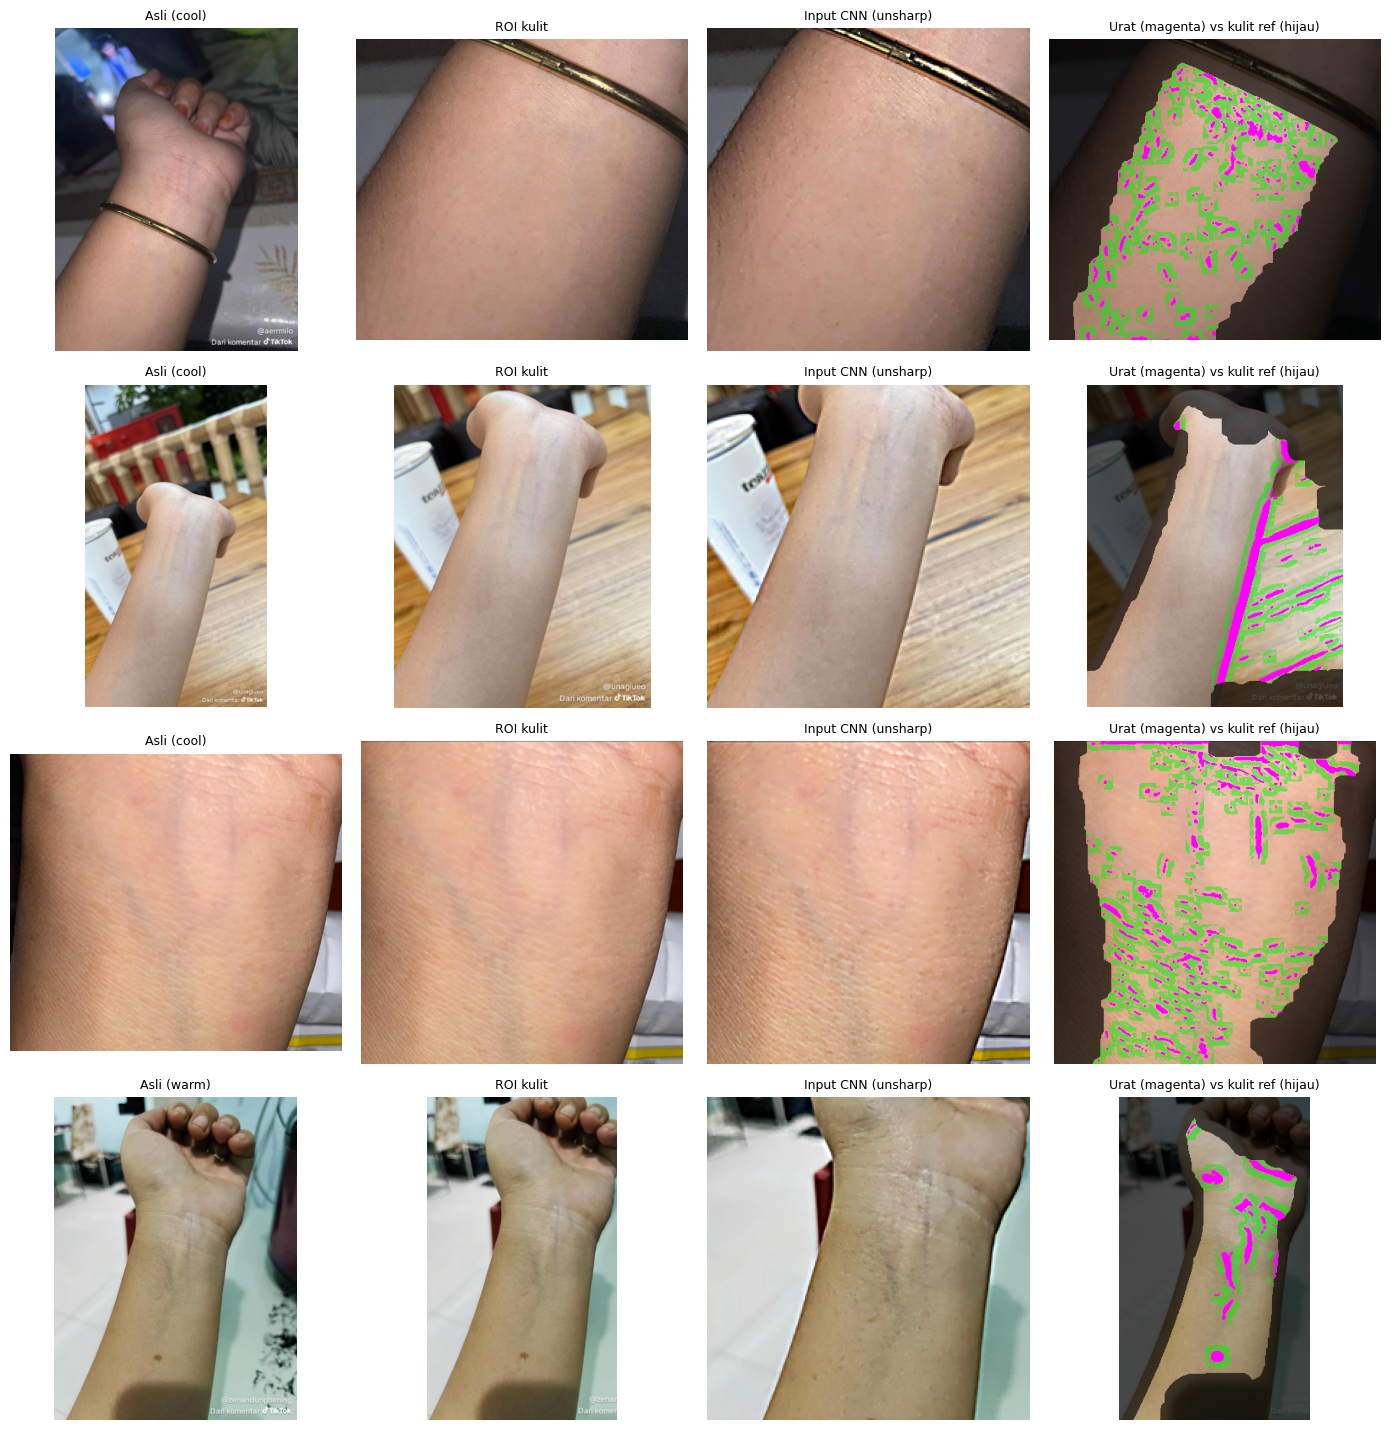

In [6]:
# ========================================================
# 6. VISUALISASI PRE-PROCESSING: ASLI | ROI | DITAJAMKAN | MASKER KULIT & URAT
# ========================================================
def show_preprocessing(n=4, seed=SEED):
    rng = random.Random(seed)
    idx = rng.sample(range(len(df)), k=min(n, len(df)))
    fig, axes = plt.subplots(len(idx), 4, figsize=(14, 3.6 * len(idx)))
    axes = np.atleast_2d(axes)
    for r, i in enumerate(idx):
        orig = load_image(df.path[i], 768)
        roi = ROIS[i]
        rgb, lab, interior, vein, skin_ref = segment(roi)
        ov = rgb.copy()
        ov[~interior] = ov[~interior] // 3
        ov[skin_ref] = (ov[skin_ref] * 0.5 + np.array([0, 120, 0])).astype(np.uint8)
        ov[vein] = [255, 0, 255]
        panels = [(orig, f"Asli ({CLASS_NAMES[df.label[i]]})"), (roi, "ROI kulit"),
                  (sharpen(center_crop(resize_short(roi, IMG_SIZE), IMG_SIZE)), "Input CNN (unsharp)"),
                  (ov, "Urat (magenta) vs kulit ref (hijau)")]
        for c, (im, title) in enumerate(panels):
            axes[r, c].imshow(im); axes[r, c].set_title(title, fontsize=9); axes[r, c].axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "preprocessing_examples.png"), dpi=110)
    plt.show()

show_preprocessing()

🎨 61 fitur warna dari 857 gambar (44.4s)

📊 Fitur warna paling membedakan kelas (ANOVA F, data DEV):
        feature      F  p_value  mean_cool  mean_neutral  mean_warm
 skin_hsv_V_p50 37.246      0.0 207.048996    197.834000 184.673004
skin_hsv_V_mean 35.360      0.0 204.585999    195.914993 183.386993
     vein_lab_a 35.014      0.0  11.241000      7.952000   7.608000
 skin_hsv_V_p10 33.877      0.0 178.955994    171.059998 152.453003
   vein_hue_sin 32.289      0.0   0.273000      0.316000   0.398000
 skin_lab_L_p10 29.402      0.0  62.594002     61.797001  54.450001
 skin_lab_a_p10 29.012      0.0   7.026000      4.500000   4.149000
 skin_lab_a_p50 28.925      0.0   9.932000      6.990000   6.825000
       skin_ITA 28.901      0.0  57.415001     60.320000  46.682999
 skin_lab_L_p50 28.521      0.0  73.001999     71.943001  66.875999
skin_lab_a_mean 28.398      0.0   9.964000      7.161000   6.977000
skin_lab_L_mean 27.900      0.0  72.266998     71.242996  66.295998
     vein_lab_L

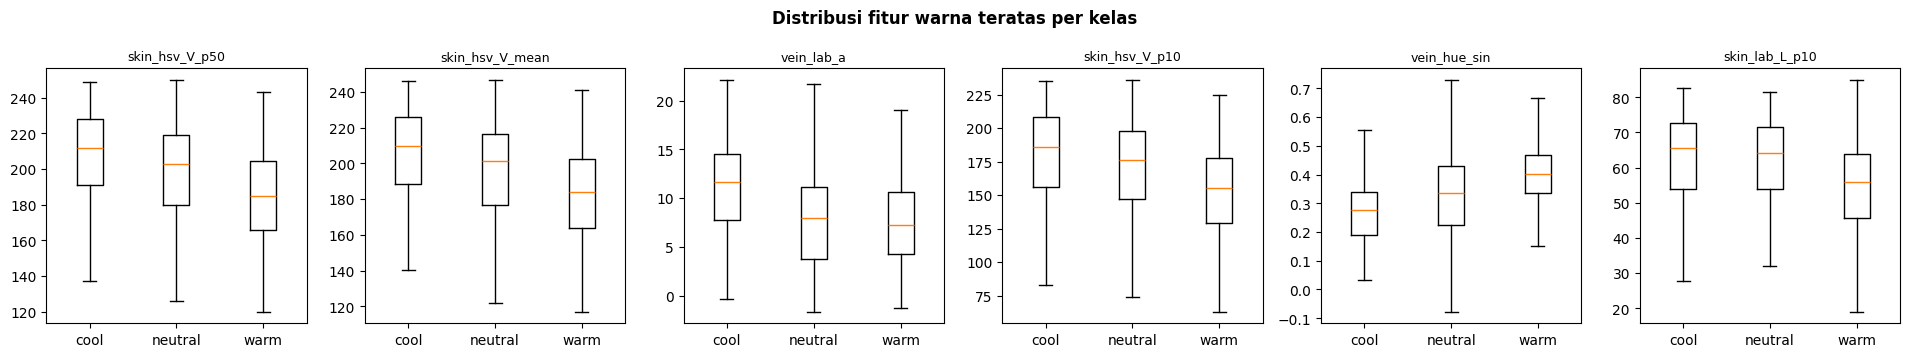

In [7]:
# ========================================================
# 7. FITUR WARNA (CIELab, HSV, YCrCb, URAT-vs-KULIT) & ANALISIS STATISTIK
# ========================================================
t0 = time.time()
_cf = [color_features(r) for r in ROIS]
COLOR_X = np.stack([v for v, _ in _cf]).astype(np.float32)
COLOR_NAMES = _cf[0][1]
print(f"🎨 {COLOR_X.shape[1]} fitur warna dari {len(ROIS)} gambar ({time.time()-t0:.1f}s)")

dev_mask  = df["split"].isin(["train", "valid"]).values
test_mask = (df["split"] == "test").values
DEV, TEST = np.where(dev_mask)[0], np.where(test_mask)[0]
y_all = df["label"].values
y_dev, y_test = y_all[DEV], y_all[TEST]
g_dev = GROUPS[DEV]

# ANOVA F-test hanya di DEV (test tidak diintip)
Fv, pv = f_classif(COLOR_X[DEV], y_dev)
color_stats = pd.DataFrame({"feature": COLOR_NAMES, "F": Fv, "p_value": pv})
for k, c in enumerate(CLASS_NAMES):
    color_stats[f"mean_{c}"] = [COLOR_X[DEV][y_dev == k, j].mean() for j in range(len(COLOR_NAMES))]
color_stats = color_stats.sort_values("F", ascending=False).reset_index(drop=True)
print("\n📊 Fitur warna paling membedakan kelas (ANOVA F, data DEV):")
print(color_stats.head(15).round(3).to_string(index=False))

top = color_stats.feature.head(6).tolist()
fig, axes = plt.subplots(1, len(top), figsize=(3.2 * len(top), 3.6))
for ax, f in zip(axes, top):
    j = COLOR_NAMES.index(f)
    ax.boxplot([COLOR_X[DEV][y_dev == k, j] for k in range(len(CLASS_NAMES))], showfliers=False)
    ax.set_xticks(range(1, len(CLASS_NAMES) + 1)); ax.set_xticklabels(CLASS_NAMES)
    ax.set_title(f, fontsize=9)
plt.suptitle("Distribusi fitur warna teratas per kelas", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "color_feature_boxplots.png"), dpi=110); plt.show()

In [8]:
# ========================================================
# 8. EKSTRAKSI FITUR MULTI-BACKBONE (FROZEN, PRETRAINED) + POOLING GAP & GeM + TTA
# ========================================================
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_tensor_norm = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

TV_SPECS = {
    "convnext_tiny":      (tvm.convnext_tiny,      "ConvNeXt_Tiny_Weights"),
    "efficientnet_v2_s":  (tvm.efficientnet_v2_s,  "EfficientNet_V2_S_Weights"),
    "resnet50":           (tvm.resnet50,           "ResNet50_Weights"),
    "mobilenet_v3_large": (tvm.mobilenet_v3_large, "MobileNet_V3_Large_Weights"),
}

def gem(x, p=3.0, eps=1e-6):
    """Generalized-Mean pooling: di antara average (p=1) dan max (p->inf) pooling."""
    return F.relu(x).clamp(min=eps).pow(p).mean(dim=(2, 3)).pow(1.0 / p)

class Extractor:
    def __init__(self, name):
        self.name = name
        if name == "dinov2_vits14":
            self.model = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True,
                                           num_classes=0, img_size=IMG_SIZE)
            self.kind = "vit"
        else:
            fn, wname = TV_SPECS[name]
            m = fn(weights=getattr(tvm, wname).DEFAULT)
            self.model = nn.Sequential(*list(m.children())[:-2]) if name.startswith("resnet") else m.features
            self.kind = "cnn"
        self.model.eval().to(device)

    @torch.no_grad()
    def __call__(self, x):
        with torch.autocast(device_type=device.type, enabled=USE_AMP):
            if self.kind == "vit":
                t = self.model.forward_features(x).float()
                npt = getattr(self.model, "num_prefix_tokens", 1)
                a, b = t[:, npt:].mean(1), t[:, 0]          # mean patch token (≈GAP) & CLS token
            else:
                f = self.model(x).float()
                a, b = f.mean(dim=(2, 3)), gem(f)           # GAP & GeM
        return a.float(), b.float()

def extract_backbone(name):
    cache = os.path.join(FEAT_CACHE_DIR, f"{name}_s{IMG_SIZE}_t{N_TTA}_n{len(df)}_roi{int(USE_ROI_CROP)}.npz")
    if os.path.exists(cache):
        z = np.load(cache)
        return z["a"], z["b"]
    ext = Extractor(name)
    A, B = [], []
    for i in range(0, len(ROIS), EXTRACT_BATCH):
        batch = ROIS[i:i + EXTRACT_BATCH]
        views = [v for im in batch for v in tta_views(im)]
        x = torch.stack([to_tensor_norm(v) for v in views]).to(device)
        a, b = ext(x)
        V = len(views) // len(batch)
        A.append(a.reshape(len(batch), V, -1).mean(1).cpu().numpy())
        B.append(b.reshape(len(batch), V, -1).mean(1).cpu().numpy())
    del ext
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    A, B = np.vstack(A), np.vstack(B)
    np.savez(cache, a=A, b=B)
    return A, B

CNN_FEATS, CNN_SPLIT = {}, {}
names = list(BACKBONES) + (["dinov2_vits14"] if (USE_DINOV2 and timm is not None) else [])
for name in names:
    t0 = time.time()
    try:
        a, b = extract_backbone(name)
    except Exception as e:
        print(f"⚠️ {name} dilewati: {e}")
        continue
    CNN_FEATS[name] = np.hstack([a, b]).astype(np.float32)
    CNN_SPLIT[name] = a.shape[1]
    print(f"✅ {name:<20} fitur {CNN_FEATS[name].shape[1]:>5} dim ({time.time()-t0:.0f}s)")
assert CNN_FEATS, "Tidak ada backbone yang berhasil. Aktifkan Internet di Kaggle untuk mengunduh bobot."

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 238MB/s] 


✅ convnext_tiny        fitur  1536 dim (52s)
Downloading: "https://download.pytorch.org/models/efficientnet_v2_s-dd5fe13b.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_v2_s-dd5fe13b.pth


100%|██████████| 82.7M/82.7M [00:00<00:00, 162MB/s]


✅ efficientnet_v2_s    fitur  2560 dim (44s)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 162MB/s]


... (2 outputs left out)

✅ mobilenet_v3_large   fitur  1920 dim (40s)


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

✅ dinov2_vits14        fitur   768 dim (42s)


In [9]:
# ========================================================
# 9. FRAMEWORK K-FOLD: STRATIFIED GROUP K-FOLD (5x2), MODEL ZOO, EVALUASI GAP
# ========================================================
cv_splits = []
for r in range(N_REPEATS):
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + r)
    cv_splits += list(sgkf.split(np.zeros(len(DEV)), y_dev, g_dev))
TUNE_SPLITS = cv_splits[:N_FOLDS]
print(f"🔁 {len(cv_splits)} split CV ({N_FOLDS}-fold x {N_REPEATS}) pada {len(DEV)} gambar DEV; TEST {len(TEST)} gambar disimpan")

def build_features(cnn_names=(), color_cols=None, pooling="both"):
    """Gabungkan blok fitur. color_cols: None=tanpa warna, 'all' atau array indeks."""
    blocks, n_cnn = [], 0
    for n in cnn_names:
        Fm, k = CNN_FEATS[n], CNN_SPLIT[n]
        Fm = Fm[:, :k] if pooling == "gap" else Fm[:, k:] if pooling == "gem" else Fm
        blocks.append(Fm); n_cnn += Fm.shape[1]
    n_col = 0
    if color_cols is not None:
        C = COLOR_X if isinstance(color_cols, str) else COLOR_X[:, color_cols]
        blocks.append(C); n_col = C.shape[1]
    return np.hstack(blocks).astype(np.float32), n_cnn, n_col

def _xgb_kwargs():
    use_gpu = GPU_AVAILABLE
    if xgb is not None and int(xgb.__version__.split(".")[0]) >= 2:
        return {"tree_method": "hist", "device": "cuda" if use_gpu else "cpu"}
    return {"tree_method": "gpu_hist" if use_gpu else "hist"}

def make_clf(name, p):
    if name == "logreg":
        return LogisticRegression(C=p.get("C", 0.1), max_iter=5000, class_weight="balanced")
    if name == "svm":
        return SVC(C=p.get("C", 1.0), gamma=p.get("gamma", "scale"), probability=True,
                   class_weight="balanced", random_state=SEED)
    if name in ("rf", "extratrees"):
        cls = RandomForestClassifier if name == "rf" else ExtraTreesClassifier
        mf = p.get("max_features", "sqrt")
        mf = float(mf) if mf not in ("sqrt", "log2") else mf
        return cls(n_estimators=p.get("n_estimators", 500), max_depth=p.get("max_depth") or None,
                   min_samples_leaf=p.get("min_samples_leaf", 3), max_features=mf,
                   class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)
    if name == "histgb":
        return HistGradientBoostingClassifier(max_depth=p.get("max_depth", 3), learning_rate=p.get("learning_rate", 0.05),
                                              max_iter=p.get("max_iter", 300), l2_regularization=p.get("l2", 1.0),
                                              class_weight="balanced", random_state=SEED)
    if name == "xgb":
        return xgb.XGBClassifier(n_estimators=p.get("n_estimators", 300), max_depth=p.get("max_depth", 3),
                                 learning_rate=p.get("learning_rate", 0.05), subsample=p.get("subsample", 0.8),
                                 colsample_bytree=p.get("colsample_bytree", 0.5), min_child_weight=p.get("min_child_weight", 3),
                                 reg_lambda=p.get("reg_lambda", 2.0), reg_alpha=p.get("reg_alpha", 0.0),
                                 objective="multi:softprob", eval_metric="mlogloss", random_state=SEED,
                                 n_jobs=-1, **_xgb_kwargs())
    if name == "lgbm":
        return lgb.LGBMClassifier(n_estimators=p.get("n_estimators", 300), num_leaves=p.get("num_leaves", 8),
                                  learning_rate=p.get("learning_rate", 0.05), subsample=p.get("subsample", 0.8),
                                  subsample_freq=1, colsample_bytree=p.get("colsample_bytree", 0.5),
                                  min_child_samples=p.get("min_child_samples", 20), reg_lambda=p.get("reg_lambda", 1.0),
                                  class_weight="balanced", random_state=SEED, verbose=-1)
    if name == "mlp":
        return MLPClassifier(hidden_layer_sizes=(p.get("hidden", 128),), alpha=p.get("alpha", 1e-2),
                             max_iter=500, early_stopping=True, n_iter_no_change=20, random_state=SEED)
    raise ValueError(name)

CLASSIFIERS = ["logreg", "svm", "rf", "extratrees", "histgb", "mlp"] + (["xgb"] if xgb else []) + (["lgbm"] if lgb else [])
DEFAULT_PCA = {"logreg": 256, "svm": 128, "mlp": 128, "rf": 64, "extratrees": 64, "histgb": 64, "xgb": 64, "lgbm": 64}

class SafePCA(PCA):
    """PCA yang otomatis membatasi n_components <= jumlah sampel (penting di fold/learning-curve kecil)."""
    def _clip(self, X):
        if isinstance(self.n_components, (int, np.integer)):
            self.n_components = int(min(self.n_components, X.shape[0] - 1, X.shape[1]))
    def fit(self, X, y=None):
        self._clip(X); return super().fit(X, y)
    def fit_transform(self, X, y=None):
        self._clip(X); return super().fit_transform(X, y)

def make_model(name, p, n_cnn, n_col):
    pca_dim = p.get("pca_dim", DEFAULT_PCA[name])
    tr = []
    if n_cnn:
        steps = [("sc", StandardScaler())]
        if pca_dim and pca_dim < n_cnn:
            steps.append(("pca", SafePCA(n_components=pca_dim, random_state=SEED)))
        tr.append(("cnn", Pipeline(steps), np.arange(n_cnn)))
    if n_col:
        tr.append(("col", StandardScaler(), np.arange(n_cnn, n_cnn + n_col)))
    return Pipeline([("prep", ColumnTransformer(tr)), ("clf", make_clf(name, p))])

def fit_model(model, name, X, y):
    if name == "xgb":
        model.fit(X, y, clf__sample_weight=compute_sample_weight("balanced", y))
    else:
        model.fit(X, y)
    return model

def cv_eval(X_all, n_cnn, n_col, name, p=None, splits=None):
    p, splits = p or {}, splits or cv_splits
    Xd = X_all[DEV]
    tr_acc, va_acc = [], []
    oof, cnt = np.zeros((len(DEV), len(CLASS_NAMES))), np.zeros(len(DEV))
    for tr, va in splits:
        m = fit_model(make_model(name, p, n_cnn, n_col), name, Xd[tr], y_dev[tr])
        pr = m.predict_proba(Xd[va])
        oof[va] += pr; cnt[va] += 1
        tr_acc.append(accuracy_score(y_dev[tr], m.predict(Xd[tr])))
        va_acc.append(accuracy_score(y_dev[va], pr.argmax(1)))
    oof /= np.maximum(cnt, 1)[:, None]
    return {"train_acc": np.mean(tr_acc), "val_acc": np.mean(va_acc), "val_std": np.std(va_acc),
            "gap": np.mean(tr_acc) - np.mean(va_acc),
            "oof_f1": f1_score(y_dev, oof.argmax(1), average="macro"), "oof": oof}

def show_table(rows, title):
    t = pd.DataFrame(rows).sort_values("val_acc", ascending=False)
    cols = [c for c in t.columns if c != "oof"]
    print(f"\n📋 {title}")
    print(t[cols].to_string(index=False, float_format=lambda v: f"{v:.3f}"))
    return t
print("✅ Framework CV siap. Classifier tersedia:", CLASSIFIERS)

🔁 10 split CV (5-fold x 2) pada 778 gambar DEV; TEST 79 gambar disimpan
✅ Framework CV siap. Classifier tersedia: ['logreg', 'svm', 'rf', 'extratrees', 'histgb', 'mlp', 'xgb', 'lgbm']


In [10]:
# ========================================================
# 10. EKSPERIMEN A — FITUR MANA YANG PALING MEMBANTU? (classifier tetap: LogReg)
# ========================================================
t0 = time.time()
rows = []
def run_fs(label, cnn_names=(), color_cols=None, pooling="both", clf="logreg"):
    X, nc, nk = build_features(cnn_names, color_cols, pooling)
    r = cv_eval(X, nc, nk, clf)
    rows.append({"features": label, "dim": X.shape[1], **r})
    return r

# A1. backbone (dengan / tanpa fitur warna)
run_fs("color only", (), "all")
for n in CNN_FEATS:
    run_fs(n, [n])
    run_fs(f"{n} + color", [n], "all")
resA1 = show_table(rows, "A1. Backbone & fitur warna (LogReg, CV 5x2)")

single = resA1[~resA1.features.str.contains(r"\+|color")].sort_values("val_acc", ascending=False)
top_bb = single.features.head(2).tolist()
rows = []
if len(CNN_FEATS) > 1:
    run_fs(" + ".join(top_bb), top_bb)
    run_fs(" + ".join(top_bb) + " + color", top_bb, "all")
    run_fs("ALL CNN + color", list(CNN_FEATS), "all")
resA1b = show_table(rows, "A1b. Kombinasi backbone terbaik") if rows else resA1.iloc[:0]

allA = pd.concat([resA1, resA1b], ignore_index=True).sort_values("val_acc", ascending=False)
best_row = allA.iloc[0]
BEST_LABEL = best_row.features
if "ALL CNN" in BEST_LABEL:
    BEST_CNN = list(CNN_FEATS)
elif BEST_LABEL.startswith("color only"):
    BEST_CNN = []
else:
    BEST_CNN = [n for n in CNN_FEATS if n in BEST_LABEL.replace(" + color", "").split(" + ")]
BEST_USE_COLOR = "color" in BEST_LABEL
print(f"\n🏆 Set fitur terbaik: {BEST_LABEL} | CV acc {best_row.val_acc:.3f} ± {best_row.val_std:.3f}")

# A2. Ablasi ruang warna (fitur warna saja) -> apakah perlu HSV & CIELab?
groups_color = {
    "CIELab saja":            [i for i, n in enumerate(COLOR_NAMES) if n.startswith("skin_lab") or n in ("skin_ITA", "skin_hab", "skin_Cab")],
    "HSV saja":               [i for i, n in enumerate(COLOR_NAMES) if "hsv" in n or "hue" in n],
    "YCrCb saja":             [i for i, n in enumerate(COLOR_NAMES) if "ycc" in n],
    "Urat-vs-kulit saja":     [i for i, n in enumerate(COLOR_NAMES) if n.startswith(("vein", "delta", "logratio"))],
    "Lab + urat":             [i for i, n in enumerate(COLOR_NAMES) if n.startswith(("skin_lab", "vein", "delta", "logratio")) or n in ("skin_ITA", "skin_hab", "skin_Cab")],
    "Semua (Lab+HSV+YCrCb+urat)": list(range(len(COLOR_NAMES))),
}
rows = []
for lbl, cols in groups_color.items():
    run_fs(lbl, (), np.array(cols))
resA2 = show_table(rows, "A2. Ablasi ruang warna (LogReg, fitur warna saja)")

# A3. Ablasi pooling pada backbone terbaik
rows = []
bb = top_bb[0] if top_bb else None
if bb:
    for pool in ["gap", "gem", "both"]:
        run_fs(f"{bb} [{pool.upper()}]", [bb], None, pool)
    resA3 = show_table(rows, f"A3. Ablasi pooling ({bb})")
print(f"\n⏱️ Eksperimen A selesai {time.time()-t0:.0f}s")

X_BEST, NC_BEST, NK_BEST = build_features(BEST_CNN, "all" if BEST_USE_COLOR else None)


📋 A1. Backbone & fitur warna (LogReg, CV 5x2)
                  features  dim  train_acc  val_acc  val_std   gap  oof_f1
     dinov2_vits14 + color  829      0.953    0.533    0.024 0.420   0.542
             dinov2_vits14  768      0.927    0.528    0.029 0.399   0.547
                color only   61      0.571    0.515    0.032 0.056   0.513
     convnext_tiny + color 1597      0.970    0.485    0.029 0.485   0.487
             convnext_tiny 1536      0.948    0.480    0.027 0.468   0.471
 efficientnet_v2_s + color 2621      0.956    0.470    0.031 0.486   0.488
         efficientnet_v2_s 2560      0.929    0.451    0.041 0.478   0.467
          resnet50 + color 4157      0.960    0.450    0.023 0.510   0.448
mobilenet_v3_large + color 1981      0.947    0.430    0.026 0.518   0.435
                  resnet50 4096      0.931    0.422    0.032 0.509   0.404
        mobilenet_v3_large 1920      0.907    0.412    0.042 0.496   0.421

📋 A1b. Kombinasi backbone terbaik
                  

In [11]:
# ========================================================
# 11. EKSPERIMEN B — CLASSIFIER MANA? (LogReg / SVM / RF / ExtraTrees / HistGB / XGBoost / LightGBM / MLP)
# ========================================================
t0 = time.time()
rows = []
for name in CLASSIFIERS:
    t1 = time.time()
    r = cv_eval(X_BEST, NC_BEST, NK_BEST, name)
    rows.append({"classifier": name, **r, "sec": time.time() - t1})
resB = show_table(rows, f"B. Perbandingan classifier pada fitur '{BEST_LABEL}'")
print("   gap = train_acc - val_acc  (gap besar = menghafal / overfitting)")
print(f"⏱️ Eksperimen B selesai {time.time()-t0:.0f}s")

resB["score"] = resB.val_acc - OVERFIT_PENALTY * np.maximum(0, resB.gap - OVERFIT_GAP_TOL)
TUNE_CANDIDATES = resB.sort_values("score", ascending=False).classifier.head(TUNE_TOP_K).tolist()
print("🎯 Akan di-tuning:", TUNE_CANDIDATES)


📋 B. Perbandingan classifier pada fitur 'dinov2_vits14 + color'
classifier  train_acc  val_acc  val_std   gap  oof_f1    sec
extratrees      1.000    0.540    0.031 0.460   0.551 16.018
      lgbm      1.000    0.540    0.028 0.460   0.558 11.972
       xgb      1.000    0.535    0.027 0.465   0.552 11.074
    logreg      0.953    0.533    0.024 0.420   0.542  9.183
        rf      1.000    0.532    0.032 0.468   0.530 26.819
    histgb      1.000    0.530    0.031 0.470   0.552 19.749
       svm      0.889    0.515    0.037 0.374   0.516  8.782
       mlp      0.898    0.497    0.032 0.402   0.518  7.124
   gap = train_acc - val_acc  (gap besar = menghafal / overfitting)
⏱️ Eksperimen B selesai 111s
🎯 Akan di-tuning: ['logreg', 'svm', 'extratrees']


In [12]:
# ========================================================
# 12. HYPERPARAMETER TUNING (Optuna / random search) DENGAN PENALTI OVERFITTING
# ========================================================
class RandomTrial:
    """Fallback bila Optuna tidak ada: API sama dengan optuna.Trial."""
    def __init__(self, rng): self.rng, self.params = rng, {}
    def suggest_float(self, k, lo, hi, log=False):
        v = float(np.exp(self.rng.uniform(np.log(lo), np.log(hi)))) if log else float(self.rng.uniform(lo, hi))
        self.params[k] = v; return v
    def suggest_int(self, k, lo, hi):
        v = int(self.rng.integers(lo, hi + 1)); self.params[k] = v; return v
    def suggest_categorical(self, k, choices):
        v = choices[int(self.rng.integers(len(choices)))]; self.params[k] = v; return v

def suggest_params(t, name, n_cnn):
    p = {}
    if n_cnn:
        p["pca_dim"] = t.suggest_categorical("pca_dim", [0, 32, 64, 128, 256])
    if name == "logreg":
        p["C"] = t.suggest_float("C", 1e-3, 10, log=True)
    elif name == "svm":
        p["C"] = t.suggest_float("C", 0.05, 50, log=True)
        p["gamma"] = t.suggest_float("gamma", 1e-4, 1e-1, log=True)
    elif name in ("rf", "extratrees"):
        p["n_estimators"] = t.suggest_int("n_estimators", 200, 800)
        p["max_depth"] = t.suggest_categorical("max_depth", [0, 4, 6, 10, 16])
        p["min_samples_leaf"] = t.suggest_int("min_samples_leaf", 1, 12)
        p["max_features"] = t.suggest_categorical("max_features", ["sqrt", "0.1", "0.3"])
    elif name == "histgb":
        p["max_depth"] = t.suggest_int("max_depth", 2, 6)
        p["learning_rate"] = t.suggest_float("learning_rate", 0.01, 0.2, log=True)
        p["max_iter"] = t.suggest_int("max_iter", 100, 500)
        p["l2"] = t.suggest_float("l2", 1e-3, 10, log=True)
    elif name == "xgb":
        p["n_estimators"] = t.suggest_int("n_estimators", 100, 800)
        p["max_depth"] = t.suggest_int("max_depth", 2, 6)
        p["learning_rate"] = t.suggest_float("learning_rate", 0.01, 0.2, log=True)
        p["subsample"] = t.suggest_float("subsample", 0.5, 1.0)
        p["colsample_bytree"] = t.suggest_float("colsample_bytree", 0.2, 1.0)
        p["min_child_weight"] = t.suggest_int("min_child_weight", 1, 10)
        p["reg_lambda"] = t.suggest_float("reg_lambda", 0.1, 20, log=True)
        p["reg_alpha"] = t.suggest_float("reg_alpha", 1e-3, 5, log=True)
    elif name == "lgbm":
        p["n_estimators"] = t.suggest_int("n_estimators", 100, 800)
        p["num_leaves"] = t.suggest_int("num_leaves", 4, 31)
        p["learning_rate"] = t.suggest_float("learning_rate", 0.01, 0.2, log=True)
        p["subsample"] = t.suggest_float("subsample", 0.5, 1.0)
        p["colsample_bytree"] = t.suggest_float("colsample_bytree", 0.2, 1.0)
        p["min_child_samples"] = t.suggest_int("min_child_samples", 5, 40)
        p["reg_lambda"] = t.suggest_float("reg_lambda", 1e-3, 20, log=True)
    elif name == "mlp":
        p["hidden"] = t.suggest_categorical("hidden", [64, 128, 256])
        p["alpha"] = t.suggest_float("alpha", 1e-4, 1.0, log=True)
    return p

def tune(name, n_trials=N_TRIALS):
    def objective(t):
        p = suggest_params(t, name, NC_BEST)
        r = cv_eval(X_BEST, NC_BEST, NK_BEST, name, p, TUNE_SPLITS)
        t.set_user_attr("val_acc", r["val_acc"]) if hasattr(t, "set_user_attr") else None
        return r["val_acc"] - OVERFIT_PENALTY * max(0.0, r["gap"] - OVERFIT_GAP_TOL)
    if optuna is not None:
        study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
        study.optimize(objective, n_trials=n_trials, show_progress_bar=False)
        best_p = suggest_params(optuna.trial.FixedTrial(study.best_params), name, NC_BEST)
        return best_p, study.best_value
    rng = np.random.default_rng(SEED)
    best = (None, -1)
    for _ in range(n_trials):
        t = RandomTrial(rng)
        s = objective(t)
        if s > best[1]:
            best = (suggest_params(_Fixed(t.params), name, NC_BEST), s)
    return best

class _Fixed(RandomTrial):
    def __init__(self, params): self.params = params
    def suggest_float(self, k, *a, **kw): return self.params[k]
    def suggest_int(self, k, *a, **kw): return self.params[k]
    def suggest_categorical(self, k, choices): return self.params[k]

t0 = time.time()
TUNED, rows = {}, []
for name in TUNE_CANDIDATES:
    t1 = time.time()
    best_p, score = tune(name)
    r = cv_eval(X_BEST, NC_BEST, NK_BEST, name, best_p)      # evaluasi ulang di 5x2 split penuh
    TUNED[name] = {"params": best_p, **r}
    rows.append({"classifier": name + " (tuned)", **r, "params": json.dumps(best_p)})
    print(f"   {name:<10} selesai {time.time()-t1:.0f}s | tune-score {score:.3f}")
resT = show_table(rows, "C. Setelah tuning (CV 5x2)")
print(f"⏱️ Tuning selesai {time.time()-t0:.0f}s ({'Optuna TPE' if optuna else 'random search'})")

   logreg     selesai 114s | tune-score 0.551
   svm        selesai 161s | tune-score 0.540
   extratrees selesai 423s | tune-score 0.530

📋 C. Setelah tuning (CV 5x2)
        classifier  train_acc  val_acc  val_std   gap  oof_f1                                                                                              params
    logreg (tuned)      0.615    0.533    0.027 0.082   0.518                                                          {"pca_dim": 32, "C": 0.008599561656269492}
       svm (tuned)      0.696    0.532    0.024 0.164   0.524                           {"pca_dim": 64, "C": 12.662138406866754, "gamma": 0.00010134229826938537}
extratrees (tuned)      0.671    0.522    0.028 0.149   0.513 {"pca_dim": 32, "n_estimators": 713, "max_depth": 0, "min_samples_leaf": 12, "max_features": "0.1"}
⏱️ Tuning selesai 698s (Optuna TPE)


In [13]:
# ========================================================
# 13. (OPSIONAL) FINE-TUNE CONVNEXT-TINY PER FOLD — augmentasi geometrik, partial freeze, label smoothing
# ========================================================
FT_OOF, FT_TEST, FT_HISTORY = None, None, []
if FINETUNE_CV and GPU_AVAILABLE:
    ft_train_tf = transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.45, 1.0), ratio=(0.75, 1.33),
                                     interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.RandomHorizontalFlip(),
        transforms.RandomVerticalFlip(p=0.3),
        transforms.RandomApply([transforms.RandomRotation(20)], p=0.5),
        transforms.RandomPerspective(distortion_scale=0.2, p=0.3),
        transforms.Lambda(sharpen),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])
    ft_eval_tf = transforms.Compose([
        transforms.Lambda(lambda im: sharpen(center_crop(resize_short(im, IMG_SIZE), IMG_SIZE))),
        transforms.ToTensor(), transforms.Normalize(MEAN, STD),
    ])

    class RoiDataset(Dataset):
        def __init__(self, idx, tf): self.idx, self.tf = idx, tf
        def __len__(self): return len(self.idx)
        def __getitem__(self, i):
            j = self.idx[i]
            return self.tf(ROIS[j]), int(y_all[j])

    def make_ft_model():
        m = tvm.convnext_tiny(weights=tvm.ConvNeXt_Tiny_Weights.DEFAULT)
        m.classifier[2] = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.classifier[2].in_features, len(CLASS_NAMES)))
        for i in range(FT_FREEZE_UPTO):
            for prm in m.features[i].parameters():
                prm.requires_grad = False
        return m.to(device)

    @torch.no_grad()
    def predict_ft(model, idxs):
        model.eval(); out = []
        for i in range(0, len(idxs), 16):
            views = [v for j in idxs[i:i + 16] for v in tta_views(ROIS[j], 4)]
            x = torch.stack([to_tensor_norm(v) for v in views]).to(device)
            with torch.autocast(device_type="cuda", enabled=USE_AMP):
                p = torch.softmax(model(x).float(), 1)
            out.append(p.reshape(-1, 4, len(CLASS_NAMES)).mean(1).cpu().numpy())
        return np.vstack(out)

    nw = 2 if ON_KAGGLE else 0
    FT_OOF = np.zeros((len(DEV), len(CLASS_NAMES)))
    FT_TEST = np.zeros((len(TEST), len(CLASS_NAMES)))
    t0 = time.time()
    for fold, (tr, va) in enumerate(TUNE_SPLITS):
        set_seed(SEED + fold)
        tr_idx, va_idx = DEV[tr], DEV[va]
        tl = DataLoader(RoiDataset(tr_idx, ft_train_tf), batch_size=FT_BATCH, shuffle=True, num_workers=nw, drop_last=True)
        vl = DataLoader(RoiDataset(va_idx, ft_eval_tf), batch_size=32, shuffle=False, num_workers=nw)
        model = make_ft_model()
        head = list(model.classifier.parameters())
        head_ids = {id(q) for q in head}
        body = [q for q in model.parameters() if q.requires_grad and id(q) not in head_ids]
        opt = torch.optim.AdamW([{"params": body, "lr": FT_LR_BACKBONE}, {"params": head, "lr": FT_LR_HEAD}], weight_decay=0.05)
        steps = FT_EPOCHS * len(tl)
        sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[FT_LR_BACKBONE, FT_LR_HEAD], total_steps=steps, pct_start=0.1)
        cw = len(tr_idx) / (len(CLASS_NAMES) * np.bincount(y_all[tr_idx], minlength=len(CLASS_NAMES)))
        crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=device), label_smoothing=0.1)
        scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)
        best_loss, best_state, bad = float("inf"), None, 0
        for ep in range(FT_EPOCHS):
            model.train(); tl_loss, tl_cor, tl_n = 0.0, 0, 0
            for x, y in tl:
                x, y = x.to(device), y.to(device)
                with torch.autocast(device_type="cuda", enabled=USE_AMP):
                    out = model(x); loss = crit(out, y)
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
                tl_loss += loss.item() * len(y); tl_cor += (out.argmax(1) == y).sum().item(); tl_n += len(y)
            model.eval(); vl_loss, vl_cor, vl_n = 0.0, 0, 0
            with torch.no_grad():
                for x, y in vl:
                    x, y = x.to(device), y.to(device)
                    with torch.autocast(device_type="cuda", enabled=USE_AMP):
                        out = model(x); loss = crit(out, y)
                    vl_loss += loss.item() * len(y); vl_cor += (out.argmax(1) == y).sum().item(); vl_n += len(y)
            FT_HISTORY.append({"fold": fold, "epoch": ep + 1, "train_loss": tl_loss / tl_n, "train_acc": tl_cor / tl_n,
                               "val_loss": vl_loss / vl_n, "val_acc": vl_cor / vl_n})
            if vl_loss / vl_n < best_loss - 1e-4:
                best_loss, bad = vl_loss / vl_n, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= FT_PATIENCE:
                    break
        model.load_state_dict(best_state)
        torch.save(best_state, os.path.join(OUTPUT_DIR, f"convnext_ft_fold{fold}.pth"))
        FT_OOF[va] = predict_ft(model, va_idx)
        FT_TEST += predict_ft(model, TEST) / len(TUNE_SPLITS)
        h = [r for r in FT_HISTORY if r["fold"] == fold]
        print(f"   Fold {fold}: epoch {len(h)} | train acc {h[-1]['train_acc']:.3f} | "
              f"val acc (TTA) {accuracy_score(y_dev[va], FT_OOF[va].argmax(1)):.3f} | {time.time()-t0:.0f}s")
        del model, opt; torch.cuda.empty_cache()
    print(f"✅ Fine-tune OOF acc: {accuracy_score(y_dev, FT_OOF.argmax(1)):.3f}")
else:
    print("ℹ️ Fine-tune dilewati (FINETUNE_CV=False atau tidak ada GPU).")

   Fold 0: epoch 9 | train acc 0.863 | val acc (TTA) 0.571 | 80s
   Fold 1: epoch 9 | train acc 0.824 | val acc (TTA) 0.583 | 124s
   Fold 2: epoch 11 | train acc 0.900 | val acc (TTA) 0.679 | 177s
   Fold 3: epoch 10 | train acc 0.873 | val acc (TTA) 0.632 | 236s
   Fold 4: epoch 10 | train acc 0.860 | val acc (TTA) 0.529 | 284s
✅ Fine-tune OOF acc: 0.599


In [14]:
# ========================================================
# 14. ENSEMBLE (bobot dari OOF, BUKAN dari test) + EVALUASI TEST SEKALI
# ========================================================
CAND = {f"{n} (tuned)": {"oof": v["oof"], "kind": "sk", "name": n, "params": v["params"]} for n, v in TUNED.items()}
if FT_OOF is not None:
    CAND["convnext_finetune"] = {"oof": FT_OOF, "kind": "ft"}
cand_names = list(CAND)
P_oof = np.stack([CAND[k]["oof"] for k in cand_names])           # (M, N, C)

def ens_probs(w, P):
    return np.tensordot(w, P, axes=1)

def objective_w(z):
    w = np.exp(z) / np.exp(z).sum()
    return log_loss(y_dev, np.clip(ens_probs(w, P_oof), 1e-7, 1), labels=range(len(CLASS_NAMES)))

res = minimize(objective_w, np.zeros(len(cand_names)), method="Nelder-Mead", options={"maxiter": 2000})
W = np.exp(res.x) / np.exp(res.x).sum()
ens_oof_acc = accuracy_score(y_dev, ens_probs(W, P_oof).argmax(1))
single_accs = {k: accuracy_score(y_dev, CAND[k]["oof"].argmax(1)) for k in cand_names}
best_single = max(single_accs, key=single_accs.get)
if ens_oof_acc < single_accs[best_single]:
    W = np.array([1.0 if k == best_single else 0.0 for k in cand_names])
    print(f"ℹ️ Ensemble tidak lebih baik dari {best_single} di OOF -> pakai model tunggal")
W = np.where(W < 1e-3, 0.0, W); W = W / W.sum()
print("⚖️ Bobot ensemble:", {k: round(float(w), 3) for k, w in zip(cand_names, W)})
print(f"   OOF acc ensemble: {accuracy_score(y_dev, ens_probs(W, P_oof).argmax(1)):.3f} | terbaik tunggal: {best_single} {single_accs[best_single]:.3f}")

# ---- Fit akhir di seluruh DEV, prediksi TEST
FINAL_MODELS, P_test, summary = {}, [], []
for k in cand_names:
    c = CAND[k]
    if c["kind"] == "sk":
        m = fit_model(make_model(c["name"], c["params"], NC_BEST, NK_BEST), c["name"], X_BEST[DEV], y_dev)
        FINAL_MODELS[k] = m
        pt = m.predict_proba(X_BEST[TEST])
        tr_acc = accuracy_score(y_dev, m.predict(X_BEST[DEV]))
        cv_acc, cv_std = TUNED[c["name"]]["val_acc"], TUNED[c["name"]]["val_std"]
    else:
        pt = FT_TEST
        last = pd.DataFrame(FT_HISTORY).groupby("fold").tail(1)
        tr_acc, cv_acc, cv_std = last.train_acc.mean(), single_accs[k], np.nan
    P_test.append(pt)
    summary.append({"model": k, "train_acc": tr_acc, "cv_acc": cv_acc, "cv_std": cv_std,
                    "test_acc": accuracy_score(y_test, pt.argmax(1)),
                    "test_f1": f1_score(y_test, pt.argmax(1), average="macro")})
P_test = np.stack(P_test)
P_ens_test = ens_probs(W, P_test)
y_pred = P_ens_test.argmax(1)
summary.append({"model": "ENSEMBLE", "train_acc": np.nan,
                "cv_acc": accuracy_score(y_dev, ens_probs(W, P_oof).argmax(1)), "cv_std": np.nan,
                "test_acc": accuracy_score(y_test, y_pred), "test_f1": f1_score(y_test, y_pred, average="macro")})
SUMMARY = pd.DataFrame(summary)
print("\n📊 Ringkasan (train = fit di seluruh DEV, cv = out-of-fold, test = hold-out sekali pakai)")
print(SUMMARY.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("\n" + "=" * 60 + "\n📋 TEST SET — ENSEMBLE\n" + "=" * 60)
print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
final_metrics = {
    "accuracy": accuracy_score(y_test, y_pred) * 100,
    "macro_precision": precision_score(y_test, y_pred, average="macro", zero_division=0) * 100,
    "macro_recall": recall_score(y_test, y_pred, average="macro", zero_division=0) * 100,
    "macro_f1": f1_score(y_test, y_pred, average="macro", zero_division=0) * 100,
    "confusion_matrix": sk_confusion_matrix(y_test, y_pred, labels=range(len(CLASS_NAMES))).tolist(),
}
n_test = len(y_test)
se = math.sqrt(max(final_metrics["accuracy"] / 100 * (1 - final_metrics["accuracy"] / 100), 1e-9) / max(n_test, 1)) * 100
print(f"🎯 Test accuracy {final_metrics['accuracy']:.2f}% (±{1.96*se:.1f}% CI95, n={n_test}) | Macro F1 {final_metrics['macro_f1']:.2f}%")

⚖️ Bobot ensemble: {'logreg (tuned)': 0.0, 'svm (tuned)': 0.171, 'extratrees (tuned)': 0.0, 'convnext_finetune': 0.829}
   OOF acc ensemble: 0.605 | terbaik tunggal: convnext_finetune 0.599

📊 Ringkasan (train = fit di seluruh DEV, cv = out-of-fold, test = hold-out sekali pakai)
             model  train_acc  cv_acc  cv_std  test_acc  test_f1
    logreg (tuned)      0.600   0.533   0.027     0.595    0.582
       svm (tuned)      0.677   0.532   0.024     0.608    0.584
extratrees (tuned)      0.683   0.522   0.028     0.544    0.530
 convnext_finetune      0.864   0.599     NaN     0.671    0.664
          ENSEMBLE        NaN   0.605     NaN     0.696    0.690

📋 TEST SET — ENSEMBLE
              precision    recall  f1-score   support

        cool     0.5882    0.7692    0.6667        13
     neutral     0.7297    0.6923    0.7105        39
        warm     0.7200    0.6667    0.6923        27

    accuracy                         0.6962        79
   macro avg     0.6793    0.7094  

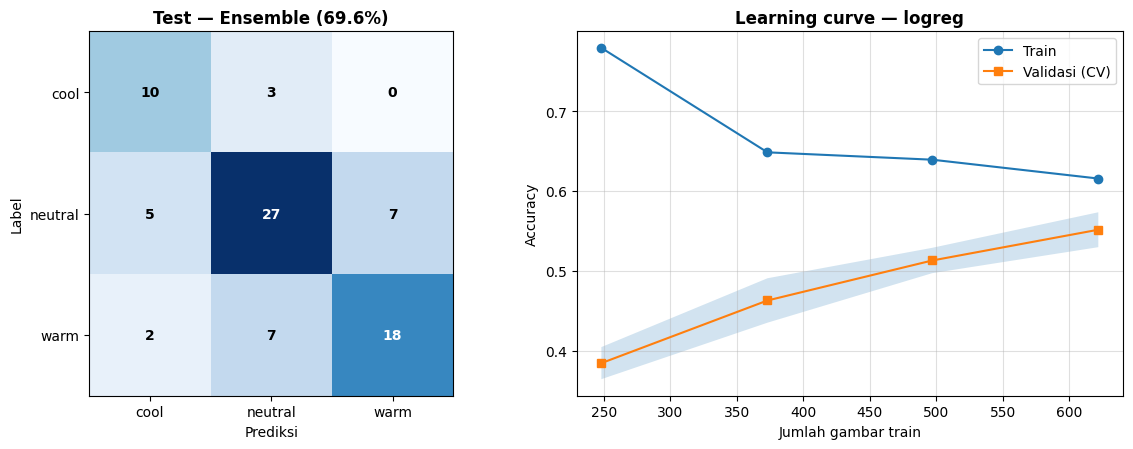

📈 Kenaikan val-acc per +100 gambar (ujung kurva): +3.56 poin
📉 Gap train-val di ukuran penuh: 0.064
   -> UNDERFIT: fitur kurang informatif; perbaiki kualitas foto/label atau fine-tune backbone.
   -> Kurva validasi masih naik: MENAMBAH DATA kemungkinan besar meningkatkan akurasi.


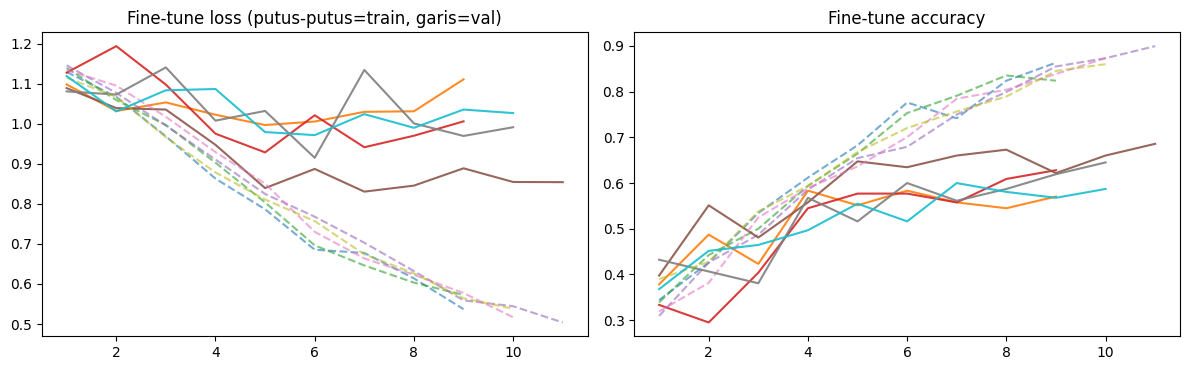

In [15]:
# ========================================================
# 15. DIAGNOSTIK: CONFUSION MATRIX, KURVA FINE-TUNE, LEARNING CURVE (OVER/UNDERFITTING)
# ========================================================
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
cm = np.array(final_metrics["confusion_matrix"])
axes[0].imshow(cm, cmap=plt.cm.Blues)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        axes[0].text(j, i, cm[i, j], ha="center", va="center", fontweight="bold",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
axes[0].set_xticks(range(len(CLASS_NAMES))); axes[0].set_xticklabels(CLASS_NAMES)
axes[0].set_yticks(range(len(CLASS_NAMES))); axes[0].set_yticklabels(CLASS_NAMES)
axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Label"); axes[0].set_title(f"Test — Ensemble ({final_metrics['accuracy']:.1f}%)", fontweight="bold")

# Learning curve model sklearn terbaik
lc_name = max(TUNED, key=lambda n: TUNED[n]["val_acc"])
lc_model = make_model(lc_name, TUNED[lc_name]["params"], NC_BEST, NK_BEST)
sizes, tr_sc, va_sc = learning_curve(lc_model, X_BEST[DEV], y_dev, cv=TUNE_SPLITS,
                                     train_sizes=np.linspace(0.2, 1.0, 5), scoring="accuracy", n_jobs=1)
axes[1].plot(sizes, tr_sc.mean(1), "o-", label="Train")
axes[1].fill_between(sizes, va_sc.mean(1) - va_sc.std(1), va_sc.mean(1) + va_sc.std(1), alpha=0.2)
axes[1].plot(sizes, va_sc.mean(1), "s-", label="Validasi (CV)")
axes[1].set_xlabel("Jumlah gambar train"); axes[1].set_ylabel("Accuracy"); axes[1].grid(alpha=0.4); axes[1].legend()
axes[1].set_title(f"Learning curve — {lc_name}", fontweight="bold")
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, "diagnostics.png"), dpi=130); plt.show()

slope = (va_sc.mean(1)[-1] - va_sc.mean(1)[-3]) / max(sizes[-1] - sizes[-3], 1) * 100
gap_final = tr_sc.mean(1)[-1] - va_sc.mean(1)[-1]
print(f"📈 Kenaikan val-acc per +100 gambar (ujung kurva): {slope*100:+.2f} poin")
print(f"📉 Gap train-val di ukuran penuh: {gap_final:.3f}")
if gap_final > 0.25:
    print("   -> Masih OVERFIT: naikkan regularisasi (C lebih kecil / PCA lebih kecil / tree lebih dangkal).")
elif tr_sc.mean(1)[-1] < 0.65:
    print("   -> UNDERFIT: fitur kurang informatif; perbaiki kualitas foto/label atau fine-tune backbone.")
else:
    print("   -> Seimbang (tidak overfit/underfit berat).")
if slope > 0.5 / 100:
    print("   -> Kurva validasi masih naik: MENAMBAH DATA kemungkinan besar meningkatkan akurasi.")

if FT_HISTORY:
    h = pd.DataFrame(FT_HISTORY)
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
    for f, g in h.groupby("fold"):
        ax[0].plot(g.epoch, g.train_loss, "--", alpha=.6); ax[0].plot(g.epoch, g.val_loss, "-", alpha=.9)
        ax[1].plot(g.epoch, g.train_acc, "--", alpha=.6); ax[1].plot(g.epoch, g.val_acc, "-", alpha=.9)
    ax[0].set_title("Fine-tune loss (putus-putus=train, garis=val)"); ax[1].set_title("Fine-tune accuracy")
    plt.tight_layout(); plt.show()

🔍 42 dari 778 gambar DEV dicurigai salah label (5.4%) -> /kaggle/working/label_audit_suspects.csv
   Tinjau gambar-gambar ini secara manual. Label yang konsisten adalah cara paling efektif menaikkan akurasi.


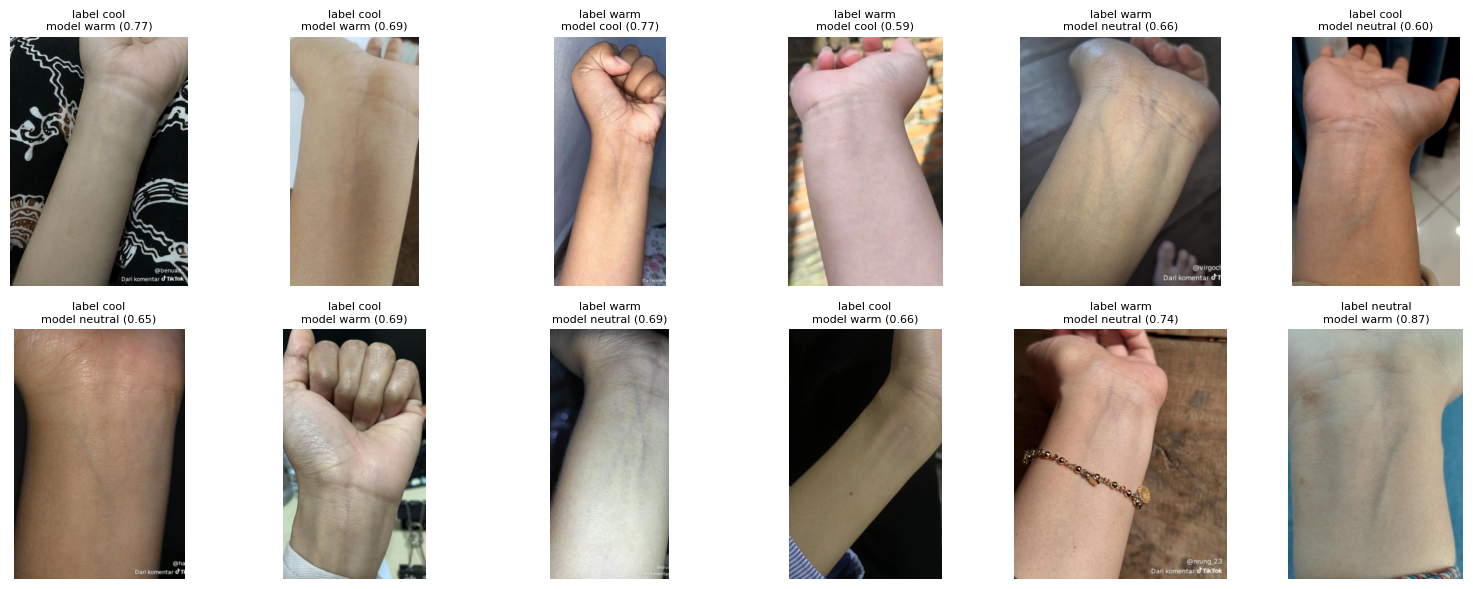

In [16]:
# ========================================================
# 16. AUDIT LABEL — gambar yang konsisten "ditolak" model (kandidat salah label)
# ========================================================
P_dev_ens = ens_probs(W, P_oof)
p_given = P_dev_ens[np.arange(len(DEV)), y_dev]
pred = P_dev_ens.argmax(1)
audit = pd.DataFrame({"path": df.path.values[DEV], "split": df.split.values[DEV],
                      "label": [CLASS_NAMES[i] for i in y_dev], "pred": [CLASS_NAMES[i] for i in pred],
                      "p_label": p_given, "p_pred": P_dev_ens.max(1)})
suspect = audit[(audit.p_label < 0.20) & (audit.p_pred > 0.55)].sort_values("p_label")
suspect.to_csv(os.path.join(OUTPUT_DIR, "label_audit_suspects.csv"), index=False)
print(f"🔍 {len(suspect)} dari {len(audit)} gambar DEV dicurigai salah label ({len(suspect)/len(audit)*100:.1f}%) "
      f"-> {os.path.join(OUTPUT_DIR, 'label_audit_suspects.csv')}")
print("   Tinjau gambar-gambar ini secara manual. Label yang konsisten adalah cara paling efektif menaikkan akurasi.")

show = suspect.head(12)
if len(show):
    cols = 6; rows_ = math.ceil(len(show) / cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(2.6 * cols, 3 * rows_))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes: ax.axis("off")
    pos = {p: i for i, p in enumerate(df.path)}
    for ax, (_, r) in zip(axes, show.iterrows()):
        ax.imshow(ROIS[pos[r.path]]); ax.set_title(f"label {r.label}\nmodel {r.pred} ({r.p_pred:.2f})", fontsize=8)
    plt.tight_layout(); plt.show()

In [17]:
# ========================================================
# 17. SIMPAN MODEL & FUNGSI PREDIKSI SATU GAMBAR
# ========================================================
bundle = {"class_names": CLASS_NAMES, "best_cnn": BEST_CNN, "use_color": BEST_USE_COLOR,
          "weights": dict(zip(cand_names, W.tolist())), "models": FINAL_MODELS,
          "img_size": IMG_SIZE, "n_tta": N_TTA, "use_roi": USE_ROI_CROP, "color_names": COLOR_NAMES}
joblib.dump(bundle, os.path.join(OUTPUT_DIR, "undertone_ensemble.joblib"))
print("💾 Disimpan:", os.path.join(OUTPUT_DIR, "undertone_ensemble.joblib"))

_EXTRACTORS = {}
def _feat_single(roi):
    parts = []
    for n in BEST_CNN:
        if n not in _EXTRACTORS:
            _EXTRACTORS[n] = Extractor(n)
        views = tta_views(roi)
        a, b = _EXTRACTORS[n](torch.stack([to_tensor_norm(v) for v in views]).to(device))
        parts.append(np.hstack([a.mean(0).cpu().numpy(), b.mean(0).cpu().numpy()]))
    if BEST_USE_COLOR:
        parts.append(color_features(roi)[0])
    return np.hstack(parts)[None].astype(np.float32)

def predict_image(path):
    img = load_image(path)
    roi = crop_roi(img) if USE_ROI_CROP else img
    roi.thumbnail((CACHE_MAX, CACHE_MAX), Image.BICUBIC)
    x = _feat_single(roi)
    probs = np.zeros(len(CLASS_NAMES))
    for k, w in zip(cand_names, W):
        if w < 1e-3:
            continue
        if k in FINAL_MODELS:
            probs += w * FINAL_MODELS[k].predict_proba(x)[0]
        elif k == "convnext_finetune":
            pf = []
            for fold in range(len(TUNE_SPLITS)):
                m = make_ft_model(); m.load_state_dict(torch.load(os.path.join(OUTPUT_DIR, f"convnext_ft_fold{fold}.pth"), map_location=device))
                m.eval()
                with torch.no_grad():
                    xx = torch.stack([to_tensor_norm(v) for v in tta_views(roi, 4)]).to(device)
                    pf.append(torch.softmax(m(xx).float(), 1).mean(0).cpu().numpy())
            probs += w * np.mean(pf, axis=0)
    return {c: round(float(p), 4) for c, p in zip(CLASS_NAMES, probs)}

if len(TEST):
    sample = df.path.values[TEST[0]]
    print(os.path.basename(sample), "->", predict_image(sample), "| label:", CLASS_NAMES[y_test[0]])

💾 Disimpan: /kaggle/working/undertone_ensemble.joblib
1765001237948_2_jpg.rf.fc520c48885328a44ebffe45bb24cb9d.jpg -> {'cool': 0.6125, 'neutral': 0.2134, 'warm': 0.1742} | label: cool


In [18]:
# ========================================================
# 18. JAWABAN OTOMATIS BERDASARKAN HASIL RUN INI + REGISTRY LOGGING
# ========================================================
def _acc(table, key, col="features"):
    r = table[table[col] == key]
    return float(r.val_acc.iloc[0]) if len(r) else float("nan")

print("=" * 70)
print("🧾 KESIMPULAN EKSPERIMEN (angka = akurasi CV out-of-fold)")
print("=" * 70)
print(f"• Fitur warna saja (Lab+HSV+YCrCb+urat)  : {_acc(resA1, 'color only'):.3f}")
bb_rows = resA1[~resA1.features.str.contains(r'\+|color')]
if len(bb_rows):
    b = bb_rows.iloc[0]
    print(f"• Backbone terbaik (frozen)               : {b.features} {b.val_acc:.3f}")
    bc = resA1[resA1.features == f"{b.features} + color"]
    if len(bc):
        print(f"• {b.features} + fitur warna              : {bc.val_acc.iloc[0]:.3f}  "
              f"({'warna MEMBANTU' if bc.val_acc.iloc[0] > b.val_acc + 0.005 else 'warna tidak menambah banyak'})")
print(f"• Ruang warna terbaik (A2)                : {resA2.iloc[0].features} {resA2.iloc[0].val_acc:.3f}")
if "resA3" in globals():
    print(f"• Pooling terbaik (A3)                    : {resA3.iloc[0].features} {resA3.iloc[0].val_acc:.3f}")
rb = resB.sort_values("val_acc", ascending=False).iloc[0]
print(f"• Classifier terbaik (B, default)         : {rb.classifier} {rb.val_acc:.3f} (gap {rb.gap:.2f})")
for n in ("xgb", "rf"):
    r = resB[resB.classifier == n]
    if len(r):
        print(f"   - {n:<5}: val {r.val_acc.iloc[0]:.3f}, train {r.train_acc.iloc[0]:.3f}, gap {r.gap.iloc[0]:.2f}")
if FT_OOF is not None:
    print(f"• Fine-tune ConvNeXt (OOF)                : {accuracy_score(y_dev, FT_OOF.argmax(1)):.3f}")
print(f"• ENSEMBLE  — CV {SUMMARY.iloc[-1].cv_acc:.3f} | TEST {SUMMARY.iloc[-1].test_acc:.3f}")
print(f"• Kandidat salah label                    : {len(suspect)} gambar ({len(suspect)/len(audit)*100:.1f}% DEV)")

accuracy  = final_metrics["accuracy"]
precision = final_metrics["macro_precision"]
recall    = final_metrics["macro_recall"]
f1        = final_metrics["macro_f1"]

auto_log_experiment(
    env_globals=globals(),
    topic="topic-b",
    model=f"Ensemble({', '.join(k for k, w in zip(cand_names, W) if w > 0.01)}) on {BEST_LABEL}",
    objective="Klasifikasi undertone: ROI kulit + unsharp, fitur warna CIELab/HSV/YCrCb & kontras urat, multi-backbone frozen (GAP+GeM, TTA), StratifiedGroupKFold 5x2, tuning dg penalti overfit, ensemble OOF",
    dataset="skin-undertone",
    owner="Egyanta Bareka Sebayang"
)

🧾 KESIMPULAN EKSPERIMEN (angka = akurasi CV out-of-fold)
• Fitur warna saja (Lab+HSV+YCrCb+urat)  : 0.515
• Backbone terbaik (frozen)               : dinov2_vits14 0.528
• dinov2_vits14 + fitur warna              : 0.533  (warna MEMBANTU)
• Ruang warna terbaik (A2)                : Semua (Lab+HSV+YCrCb+urat) 0.515
• Pooling terbaik (A3)                    : dinov2_vits14 [GAP] 0.539
• Classifier terbaik (B, default)         : extratrees 0.540 (gap 0.46)
   - xgb  : val 0.535, train 1.000, gap 0.47
   - rf   : val 0.532, train 1.000, gap 0.47
• Fine-tune ConvNeXt (OOF)                : 0.599
• ENSEMBLE  — CV 0.605 | TEST 0.696
• Kandidat salah label                    : 42 gambar (5.4% DEV)

===REGISTRY_PAYLOAD_START===
{
  "topic": "topic-b",
  "model": "Ensemble(svm (tuned), convnext_finetune) on dinov2_vits14 + color",
  "objective": "Klasifikasi undertone: ROI kulit + unsharp, fitur warna CIELab/HSV/YCrCb & kontras urat, multi-backbone frozen (GAP+GeM, TTA), StratifiedGroupKFold 5x2